# Market axes and relative ranks

Construct flow, persistence, activity, concentration, volatility and impact axes; compare fast and slow rolling ranks.

**Status:** curated research source; original saved outputs preserved. Original notes about results are historical observations, not revalidated conclusions. Read `docs/DATA_AND_RUNNING.md` before execution.

Source: `Phase 1.ipynb`, original cells 0–26 (zero-based).


In [ ]:
from pathlib import Path
import os
import sys

# Locate the repository from its root or any notebook subdirectory.
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "tradinguni_paths.py").is_file()), None)
if REPO_ROOT is None:
    raise RuntimeError("Open this notebook from inside the TradingUni repository.")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from tradinguni_paths import data_path, output_path
os.chdir(REPO_ROOT)


In [ ]:
import polars as pl

aggbars2020 = pl.read_parquet(str(data_path("0.Data -> Facts/Binance Vision Data/aggBars/aggBars-1m-ETH-2020.parquet")))
aggbars2021 = pl.read_parquet(str(data_path("0.Data -> Facts/Binance Vision Data/aggBars/aggBars-1m-ETH-2021.parquet")))
aggbars2022 = pl.read_parquet(str(data_path("0.Data -> Facts/Binance Vision Data/aggBars/aggBars-1m-ETH-2022.parquet")))
aggbars2023 = pl.read_parquet(str(data_path("0.Data -> Facts/Binance Vision Data/aggBars/aggBars-1m-ETH-2023.parquet")))
aggbars2024 = pl.read_parquet(str(data_path("0.Data -> Facts/Binance Vision Data/aggBars/aggBars-1m-ETH-2024.parquet")))
aggbars2025 = pl.read_parquet(str(data_path("0.Data -> Facts/Binance Vision Data/aggBars/aggBars-1m-ETH-2025.parquet")))

aggbars = pl.concat([aggbars2020, aggbars2021, aggbars2022, aggbars2023, aggbars2024, aggbars2025])

In [ ]:
aggbars

t,open,high,low,close,vol_base,vol_quote,trade_count,buy_count,sell_count,buy_quote,sell_quote,signed_quote,vwap,trade_rate,imbalance,range,hl_pct,prev_close,ret_inbar,ret_cc,gap_oc,dt_mean_ms,dt_median_ms,dt_p90_ms,frac_dt0,active_ms,intensity_peak_1s,realized_var_inbar,dp0_frac,n_price_changes,up_ticks,down_ticks,max_up_move,max_down_move,n_returns,avg_trade_q,avg_trade_notional,q_p50,q_p90,q_p99,notional_p90,notional_p99,top1_share,sign_persistence_inbar,flip_count,sign_entropy,n_trans,run_max,run_mean,is_sparse_stats,is_sparse_seq,is_sparse_top1,gap_ms_from_last_trade,is_no_trade_fill,is_missing_fill
datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,u32,f64,f64,u32,u32,u32,f64,f64,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,f64,i32,i64,f64,bool,bool,bool,i64,bool,bool
2020-01-01 00:00:00,129.16,129.19,128.96,129.02,305.44687,39416.984623,90.0,27.0,63.0,12240.154502,27176.830121,-14936.675619,129.046942,1.5,-0.37894,0.23,0.001782,null,-0.001085,null,null,653.370787,260.0,1765.0,0.033708,87,7,0.000002,0.539326,41,16,25,0.06,-0.06,89,3.393854,437.966496,1.00526,7.70228,19.36258,993.748166,2499.128201,0.232843,0.764045,21,1.126515,89,27,4.090909,false,false,false,0,false,false
2020-01-01 00:01:00,128.99,129.11,128.99,129.02,118.00168,15228.324945,39.0,16.0,23.0,9995.54286,5232.782085,4762.760775,129.051764,0.65,0.312757,0.12,0.00093,129.02,0.000233,0.0,-0.000233,1428.289474,538.5,3537.0,0.078947,36,9,3.6627e-7,0.5,19,11,8,0.03,-0.03,38,3.025684,390.46987,0.31116,5.0,51.0,645.1,6580.53,null,0.631579,14,1.331309,38,13,2.6,false,false,true,0,false,false
2020-01-01 00:02:00,129.0,129.05,128.94,128.98,141.64707,18268.673987,37.0,19.0,18.0,16285.746282,1982.927705,14302.818578,128.973187,0.616667,0.782915,0.11,0.000853,129.02,-0.000155,-0.00031,-0.000155,1629.222222,970.5,4154.0,0.055556,35,5,9.1361e-7,0.25,27,13,14,0.05,-0.05,36,3.828299,493.747946,0.62237,19.0,19.38736,2450.81,2500.097226,null,0.75,9,1.253421,36,8,3.7,false,false,true,0,false,false
2020-01-01 00:03:00,128.95,129.02,128.94,128.98,29.11515,3755.064313,34.0,17.0,17.0,2057.377643,1697.686671,359.690972,128.972865,0.566667,0.095788,0.08,0.00062,128.98,0.000233,0.0,-0.000233,1763.181818,1261.0,4452.0,0.030303,33,5,6.4318e-7,0.393939,20,11,9,0.05,-0.05,33,0.856328,110.443068,0.328,2.0,8.0,257.92,1031.68,null,0.575758,14,1.373974,33,5,2.266667,false,false,true,0,false,false
2020-01-01 00:04:00,128.97,128.97,128.8,128.88,102.50335,13209.658272,52.0,25.0,27.0,7735.141044,5474.517228,2260.623816,128.870503,0.866667,0.171134,0.17,0.001319,128.98,-0.000698,-0.000776,-0.000078,1124.313725,305.0,3804.0,0.196078,42,9,0.000001,0.352941,33,13,20,0.05,-0.04,51,1.971218,254.03189,0.62262,3.49697,18.84797,450.899312,2428.372455,0.390877,0.745098,13,1.259017,51,11,3.714286,false,false,false,0,false,false
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2025-12-31 23:55:00,2971.14,2971.82,2971.13,2971.82,22.8505,67897.53557,139.0,117.0,22.0,64144.830718,3752.704852,60392.125866,2971.380739,2.316667,0.88946,0.69,0.000232,2971.13,0.000229,0.000232,0.000003,430.536232,1.0,1357.0,0.456522,76,45,1.6535e-9,0.449275,76,64,12,0.04,-0.01,138,0.164392,488.471479,0.0253,0.467,1.6908,1387.52238,5023.603512,0.152019,0.811594,26,0.841451,138,48,5.148148,false,false,false,0,false,false
2025-12-31 23:56:00,2971.82,2972.83,2971.81,2972.82,43.2258,128485.978662,193.0,170.0,23.0,98075.314425,30410.664237,67664.650188,2972.437263,3.216667,0.526631,1.02,0.000343,2971.82,0.000336,0.000336,0.0,302.208333,0.0,1015.0,0.526042,92,31,2.2411e-9,0.458333,104,91,13,0.04,-0.01,192,0.223968,665.730459,0.027,0.466,2.4086,1385.3015,7160.334252,0.239496,0.859375,27,0.685393,192,75,6.892857,false,false,false,0,false,false
2025-12-31 23:57:00,2972.83,2972.83,2971.64,2971.64,61.2318,181999.692974,181.0,43.0,138.0,65231.280412,116768.412562,-51537.13215,2972.306758,3.016667,-0.283172,1.19,0.0004,2

# Creates main axes (F,P,A,C,V,I)

In [ ]:
import polars as pl

def add_6_axes(
    aggbars: pl.DataFrame,
    bar_seconds: int | None = None,
    eps_mode: str = "vol_quote",   # "vol_quote" or "pct_signed_quote"
    eps_alpha: float = 1e-6,
    eps_pct: float = 0.01,
    eps_min: float = 1e-12,
    prefix: str = "",
    # --- robustness knobs ---
    min_active_ms_for_F: int = 100,      # กัน F blow-up ถ้า active_ms เล็กเกิน
) -> pl.DataFrame:
    """
    Creates 6 axes (F,P,A,C,V,I):

    A_t = active_ms / (1000*bar_seconds)   clipped to [0,1]
    F_t = signed_quote / active_seconds    computed only if active_ms >= min_active_ms_for_F
    P_t = 1 - sign_entropy/log(4)          clipped to [0,1], null if sign_entropy null
    C_t = top1_share
    V_t = sqrt(realized_var_inbar)         (var clipped >=0)
    I_t = |ret_inbar|*vwap / (|signed_quote| + eps)   null if missing/invalid inputs
    """

    # --- infer bar_seconds if not provided ---
    if bar_seconds is None:
        med = (
            aggbars.select(pl.col("t").diff().dt.total_seconds().drop_nulls().median())
            .item()
        )
        bar_seconds = int(med) if med and med > 0 else 60

    # ensure rolling uses correct order
    aggbars = aggbars.sort("t")  # or .set_sorted("t") if already sorted

    abs_flow = pl.col("signed_quote").abs()

    # active seconds with a true denom floor
    active_sec = pl.col("active_ms") / 1000.0

    # rolling q05 (row-based over last 120 bars)
    flow_q05 = abs_flow.rolling_quantile(
        quantile=0.05,
        window_size=120,
        min_periods=max(5, 120 // 10),
    )

    # epsilon
    if eps_mode == "vol_quote":
        eps_expr = (pl.col("vol_quote").fill_null(0.0) * float(eps_alpha)).clip(lower_bound=float(eps_min))
        eps_expr = pl.max_horizontal(eps_expr, pl.lit(float(eps_min)))  # ensure not null
    elif eps_mode == "pct_signed_quote":
        eps_value = (
            aggbars.select(abs_flow.drop_nulls().quantile(eps_pct, "nearest")).item()
        )
        eps_expr = pl.lit(max(float(eps_min), float(eps_value)))
    else:
        raise ValueError(...)

    H_max = pl.lit(4.0).log()

    return aggbars.with_columns([
        ((pl.col("active_ms") / (1000.0 * float(bar_seconds))).clip(0.0, 1.0)).alias(f"{prefix}A_t"),

        # F_t guarded
        pl.when(pl.col("active_ms") >= pl.lit(min_active_ms_for_F))
          .then(pl.col("signed_quote") / active_sec)
          .otherwise(None)
          .alias(f"{prefix}F_t"),

        pl.when(pl.col("sign_entropy").is_not_null())
          .then((1.0 - (pl.col("sign_entropy") / H_max)).clip(0.0, 1.0))
          .otherwise(None)
          .alias(f"{prefix}P_t"),

        pl.col("top1_share").alias(f"{prefix}C_t"),

        pl.when(pl.col("realized_var_inbar").is_not_null())
          .then(pl.col("realized_var_inbar").clip(lower_bound=0.0).sqrt())
          .otherwise(None)
          .alias(f"{prefix}V_t"),

        # I_t guarded: also require non-trivial flow and stable eps
        pl.when(
            pl.col("ret_inbar").is_not_null()
            & pl.col("vwap").is_not_null()
            & (pl.col("vwap") > 0)
            & pl.col("signed_quote").is_not_null()
            & (abs_flow > 0)
            & (abs_flow >= flow_q05.fill_null(0.0))
        )
        .then((pl.col("ret_inbar").abs() * pl.col("vwap")) / (abs_flow + eps_expr))
        .otherwise(None)
        .alias(f"{prefix}I_t"),

        eps_expr.alias(f"{prefix}eps_I"),
    ])

In [ ]:
state_vectors = add_6_axes(aggbars, bar_seconds=60)

/tmp/ipython-input-3035478163.py:42: DeprecationWarning: the argument `min_periods` for `Expr.rolling_quantile` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  flow_q05 = abs_flow.rolling_quantile(


In [ ]:
L_fill = 120
I = pl.col("I_t")

I_roll = I.rolling_mean(window_size=L_fill, min_periods=60)

state_vectors = state_vectors.with_columns([
    pl.when(pl.col("is_missing_fill"))
      .then(None)
      .otherwise(
          # เติมแบบจำกัด: ffill ได้แค่ช่วง no-trade fill
          I.fill_null(strategy="forward", limit=L_fill)
           .fill_null(I_roll)
      )
      .alias("I_t_filled")
])

/tmp/ipython-input-901095377.py:4: DeprecationWarning: the argument `min_periods` for `Expr.rolling_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  I_roll = I.rolling_mean(window_size=L_fill, min_periods=60)


In [ ]:
state_vectors

t,open,high,low,close,vol_base,vol_quote,trade_count,buy_count,sell_count,buy_quote,sell_quote,signed_quote,vwap,trade_rate,imbalance,range,hl_pct,prev_close,ret_inbar,ret_cc,gap_oc,dt_mean_ms,dt_median_ms,dt_p90_ms,frac_dt0,active_ms,intensity_peak_1s,realized_var_inbar,dp0_frac,n_price_changes,up_ticks,down_ticks,max_up_move,max_down_move,n_returns,avg_trade_q,avg_trade_notional,q_p50,q_p90,q_p99,notional_p90,notional_p99,top1_share,sign_persistence_inbar,flip_count,sign_entropy,n_trans,run_max,run_mean,is_sparse_stats,is_sparse_seq,is_sparse_top1,gap_ms_from_last_trade,is_no_trade_fill,is_missing_fill,A_t,F_t,P_t,C_t,V_t,I_t,eps_I,I_t_filled
datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,u32,f64,f64,u32,u32,u32,f64,f64,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,f64,i32,i64,f64,bool,bool,bool,i64,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64
2020-01-01 00:00:00,129.16,129.19,128.96,129.02,305.44687,39416.984623,90.0,27.0,63.0,12240.154502,27176.830121,-14936.675619,129.046942,1.5,-0.37894,0.23,0.001782,null,-0.001085,null,null,653.370787,260.0,1765.0,0.033708,87,7,0.000002,0.539326,41,16,25,0.06,-0.06,89,3.393854,437.966496,1.00526,7.70228,19.36258,993.748166,2499.128201,0.232843,0.764045,21,1.126515,89,27,4.090909,false,false,false,0,false,false,0.00145,null,0.187391,0.232843,0.001296,0.000009,0.039417,0.000009
2020-01-01 00:01:00,128.99,129.11,128.99,129.02,118.00168,15228.324945,39.0,16.0,23.0,9995.54286,5232.782085,4762.760775,129.051764,0.65,0.312757,0.12,0.00093,129.02,0.000233,0.0,-0.000233,1428.289474,538.5,3537.0,0.078947,36,9,3.6627e-7,0.5,19,11,8,0.03,-0.03,38,3.025684,390.46987,0.31116,5.0,51.0,645.1,6580.53,null,0.631579,14,1.331309,38,13,2.6,false,false,true,0,false,false,0.0006,null,0.039663,null,0.000605,0.000006,0.015228,0.000006
2020-01-01 00:02:00,129.0,129.05,128.94,128.98,141.64707,18268.673987,37.0,19.0,18.0,16285.746282,1982.927705,14302.818578,128.973187,0.616667,0.782915,0.11,0.000853,129.02,-0.000155,-0.00031,-0.000155,1629.222222,970.5,4154.0,0.055556,35,5,9.1361e-7,0.25,27,13,14,0.05,-0.05,36,3.828299,493.747946,0.62237,19.0,19.38736,2450.81,2500.097226,null,0.75,9,1.253421,36,8,3.7,false,false,true,0,false,false,0.000583,null,0.095848,null,0.000956,0.000001,0.018269,0.000001
2020-01-01 00:03:00,128.95,129.02,128.94,128.98,29.11515,3755.064313,34.0,17.0,17.0,2057.377643,1697.686671,359.690972,128.972865,0.566667,0.095788,0.08,0.00062,128.98,0.000233,0.0,-0.000233,1763.181818,1261.0,4452.0,0.030303,33,5,6.4318e-7,0.393939,20,11,9,0.05,-0.05,33,0.856328,110.443068,0.328,2.0,8.0,257.92,1031.68,null,0.575758,14,1.373974,33,5,2.266667,false,false,true,0,false,false,0.00055,null,0.008887,null,0.000802,0.000083,0.003755,0.000083
2020-01-01 00:04:00,128.97,128.97,128.8,128.88,102.50335,13209.658272,52.0,25.0,27.0,7735.141044,5474.517228,2260.623816,128.870503,0.866667,0.171134,0.17,0.001319,128.98,-0.000698,-0.000776,-0.000078,1124.313725,305.0,3804.0,0.196078,42,9,0.000001,0.352941,33,13,20,0.05,-0.04,51,1.971218,254.03189,0.62262,3.49697,18.84797,450.899312,2428.372455,0.390877,0.745098,13,1.259017,51,11,3.714286,false,false,false,0,false,false,0.0007,null,0.091812,0.390877,0.001067,0.00004,0.01321,0.00004
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2025-12-31 23:55:00,2971.14,2971.82,2971.13,2971.82,22.8505,67897.53557,139.0,117.0,22.0,64144.830718,3752.704852,60392.125866,2971.380739,2.316667,0.88946,0.69,0.000232,2971.13,0.000229,0.000232,0.000003,430.536232,1.0,1357.0,0.456522,76,45,1.6535e-9,0.449275,76,64,12,0.04,-0.01,138,0.164392,488.471479,0.0253,0.467,1.6908,1387.52238,5023.603512,0.152019,0.811594,26,0.841451,138,48,5.148148,false,false,false,0,false,false,0.001267,null,0.393022,0.152019,0.000041,0.000011,0.067898,0.000011
2025-12-31 23:56:00,2971.82,2972.83,2971.81,2972.82,43.2258,128485.978662,193.0,170.0,23.0,98075.314425,30410.664237,67664.

## Plot

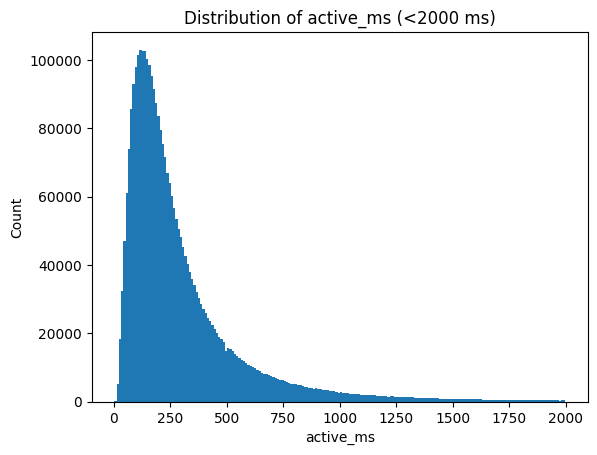

In [ ]:
import matplotlib.pyplot as plt

data = aggbars['active_ms'].drop_nulls().to_numpy()

plt.figure()
plt.hist(data[data < 2000], bins=200)
plt.title("Distribution of active_ms (<2000 ms)")
plt.xlabel("active_ms")
plt.ylabel("Count")
plt.show()

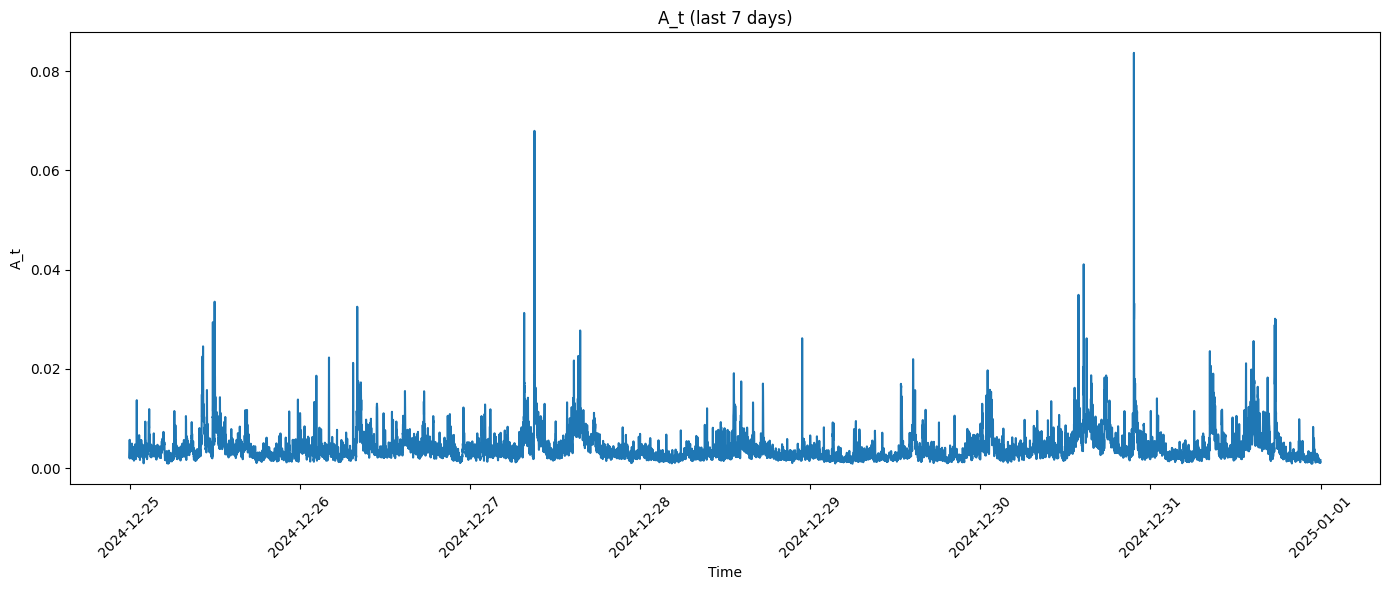

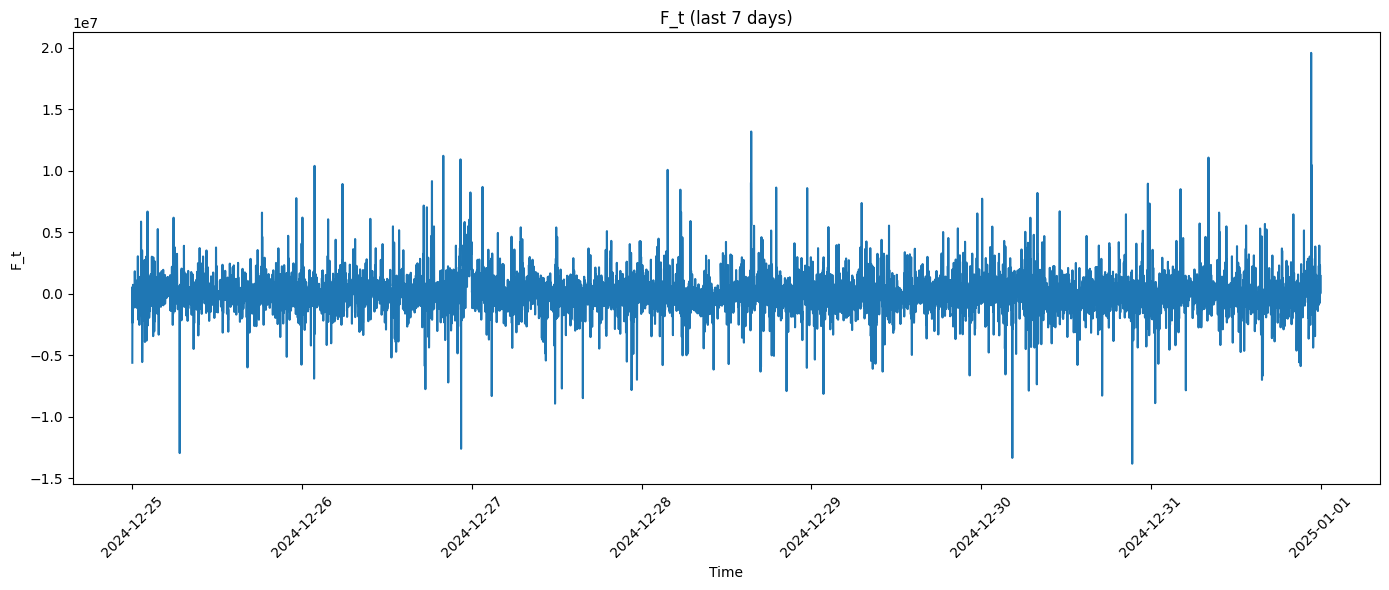

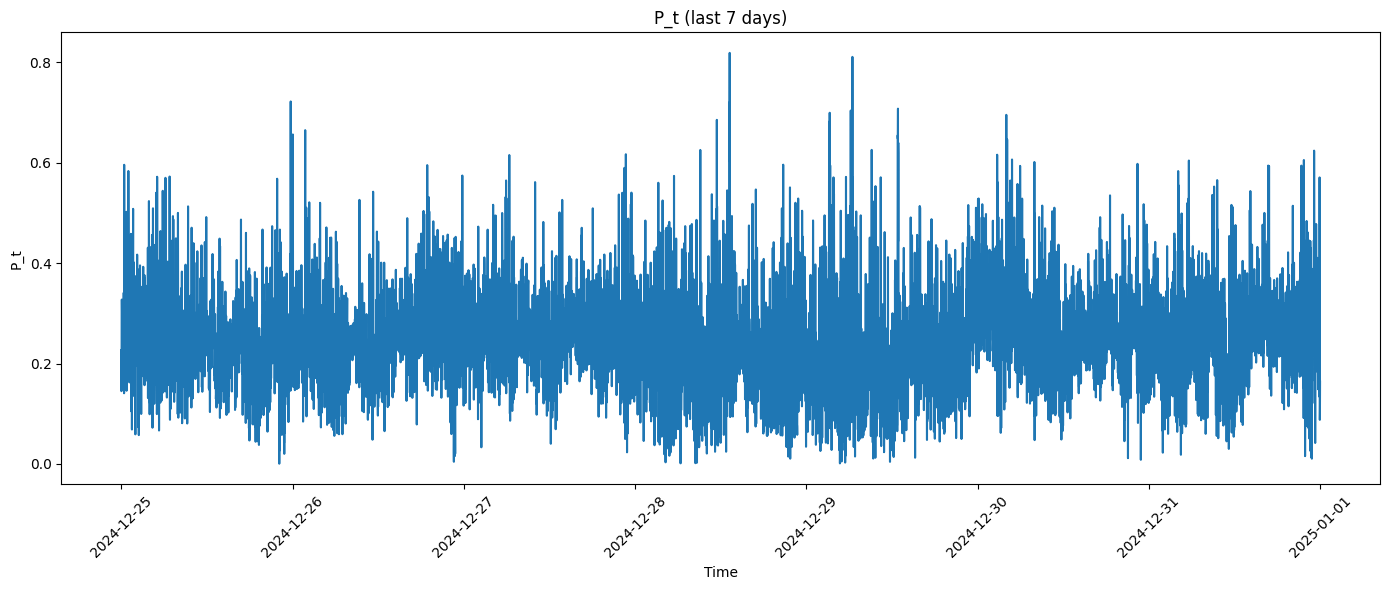

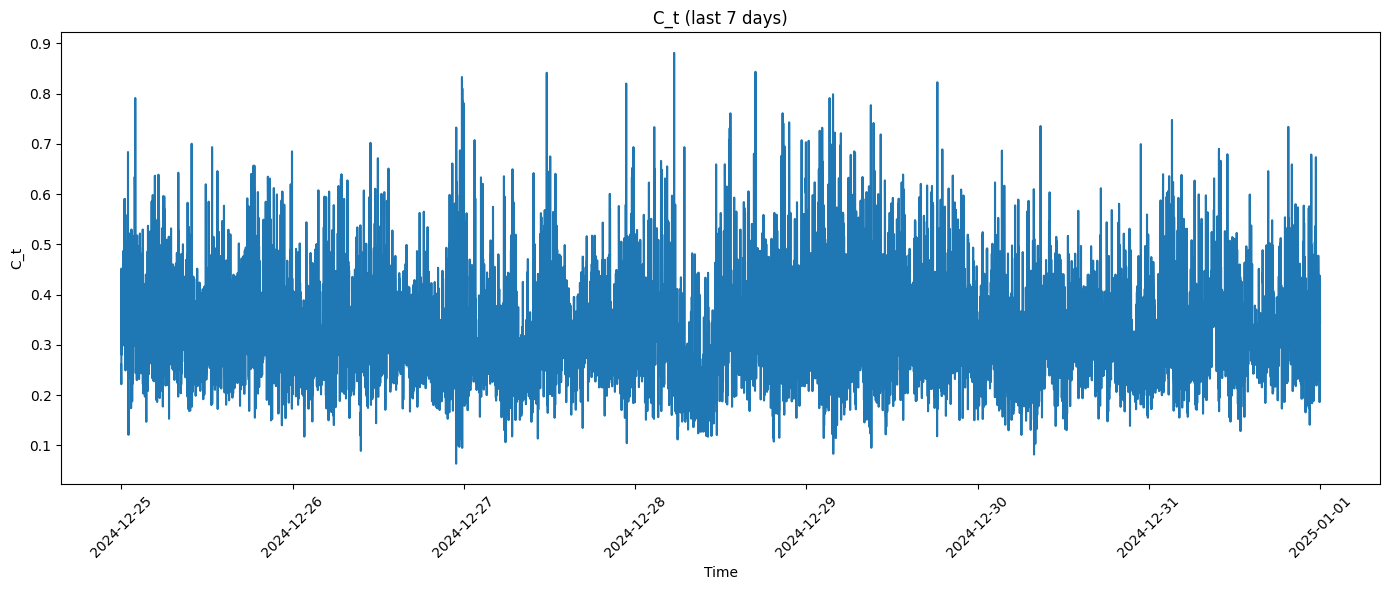

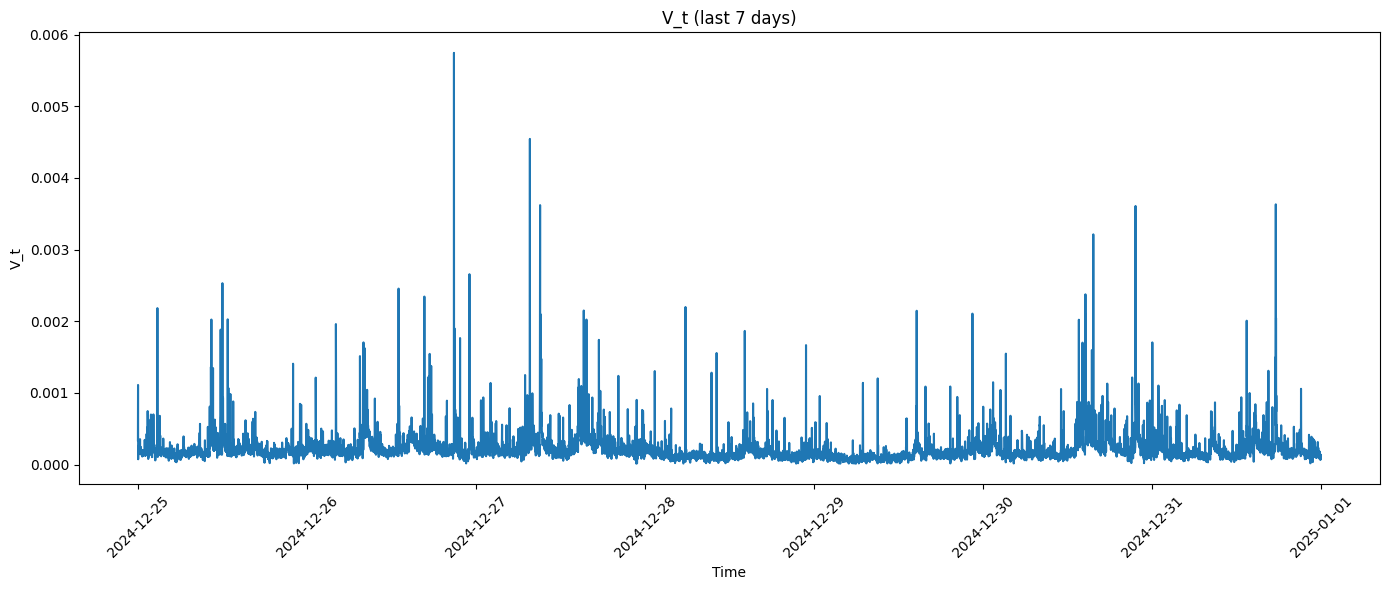

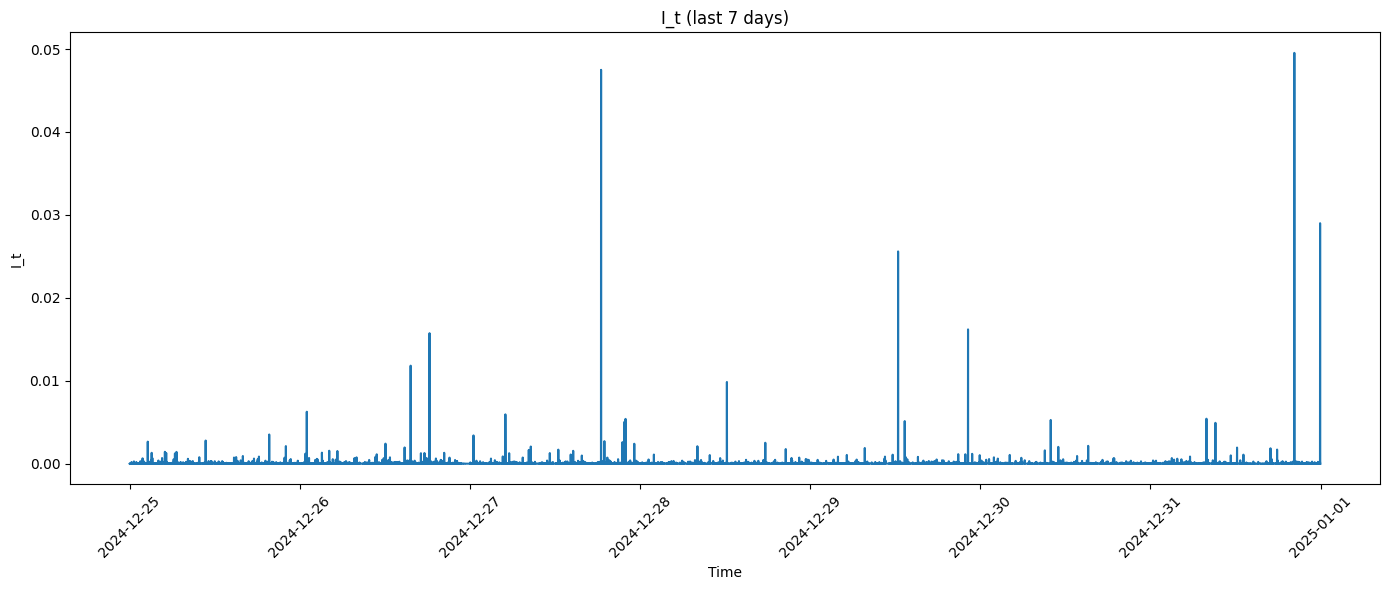

In [ ]:
import matplotlib.pyplot as plt
import polars as pl

# --- เลือกช่วงเวลา 7 วันล่าสุด ---
t_max = state_vectors.select(pl.col("t").max()).item()
t_min = t_max - pl.duration(days=7)

df_7d = (
    state_vectors
    .filter(pl.col("t") >= t_min)
    .sort("t")
)

features = ["A_t", "F_t", "P_t", "C_t", "V_t", "I_t"]

# --- plot ทีละ feature (1 plot ต่อ 1 figure) ---
for col in features:
    plt.figure(figsize=(14, 6))
    plt.plot(df_7d["t"].to_numpy(), df_7d[col].to_numpy())
    plt.title(f"{col} (last 7 days)")
    plt.xlabel("Time")
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

shape: (9, 3)
┌────────────┬────────────┬────────────┐
│ statistic  ┆ I_t        ┆ I_t_filled │
│ ---        ┆ ---        ┆ ---        │
│ str        ┆ f64        ┆ f64        │
╞════════════╪════════════╪════════════╡
│ count      ┆ 2.494264e6 ┆ 2.630869e6 │
│ null_count ┆ 136616.0   ┆ 11.0       │
│ mean       ┆ 0.000016   ┆ 0.000016   │
│ std        ┆ 0.000032   ┆ 0.000032   │
│ min        ┆ 0.0        ┆ 0.0        │
│ 25%        ┆ 0.000003   ┆ 0.000003   │
│ 50%        ┆ 0.000007   ┆ 0.000007   │
│ 75%        ┆ 0.000017   ┆ 0.000017   │
│ max        ┆ 0.002503   ┆ 0.002503   │
└────────────┴────────────┴────────────┘


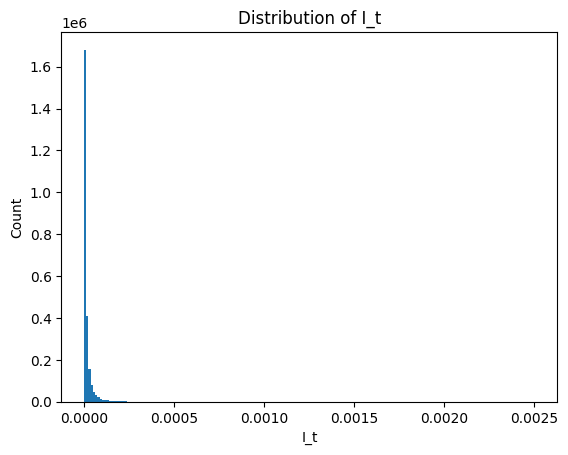

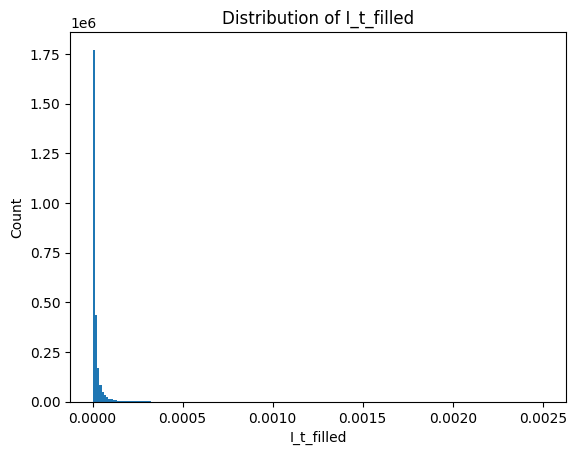

In [ ]:
import matplotlib.pyplot as plt

cols = [
    "I_t",
    "I_t_filled"
]

print(state_vectors.select(cols).describe())

for c in cols:
    data = state_vectors.select(c).to_series().drop_nulls().to_numpy()
    plt.figure()
    plt.hist(data, bins=200)
    plt.title(f"Distribution of {c}")
    plt.xlabel(c)
    plt.ylabel("Count")
    plt.show()

shape: (9, 7)
┌────────────┬────────────┬────────────┬────────────┬────────────┬────────────────┬────────────┐
│ statistic  ┆ A_t        ┆ V_t        ┆ C_t        ┆ P_t        ┆ F_t            ┆ I_t        │
│ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---            ┆ ---        │
│ str        ┆ f64        ┆ f64        ┆ f64        ┆ f64        ┆ f64            ┆ f64        │
╞════════════╪════════════╪════════════╪════════════╪════════════╪════════════════╪════════════╡
│ count      ┆ 3.153978e6 ┆ 3.153974e6 ┆ 3.093724e6 ┆ 3.151751e6 ┆ 2.668868e6     ┆ 2.992947e6 │
│ null_count ┆ 2502.0     ┆ 2506.0     ┆ 62756.0    ┆ 4729.0     ┆ 487612.0       ┆ 163533.0   │
│ mean       ┆ 0.005351   ┆ 0.000674   ┆ 0.295287   ┆ 0.149353   ┆ -8927.028411   ┆ 0.000016   │
│ std        ┆ 0.006602   ┆ 0.001932   ┆ 0.124132   ┆ 0.113825   ┆ 1.2259e6       ┆ 0.000032   │
│ min        ┆ 0.00005    ┆ 0.0        ┆ 0.026823   ┆ 0.0        ┆ -3.8130e7      ┆ 0.0        │
│ 25%        ┆ 0

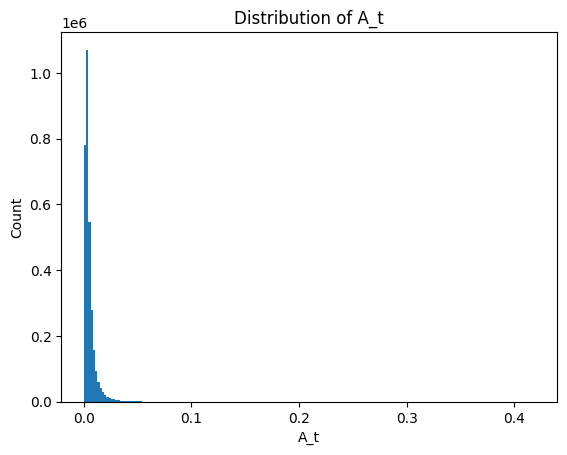

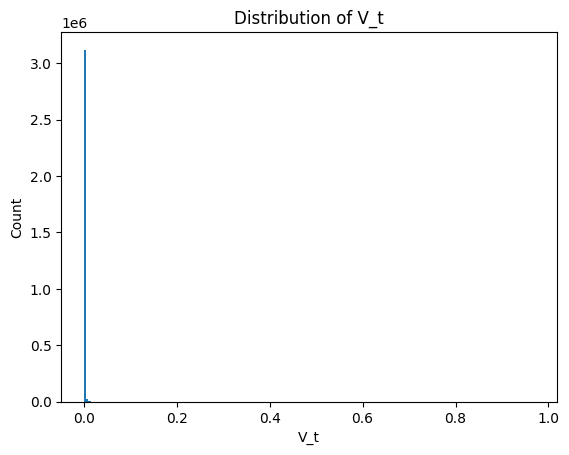

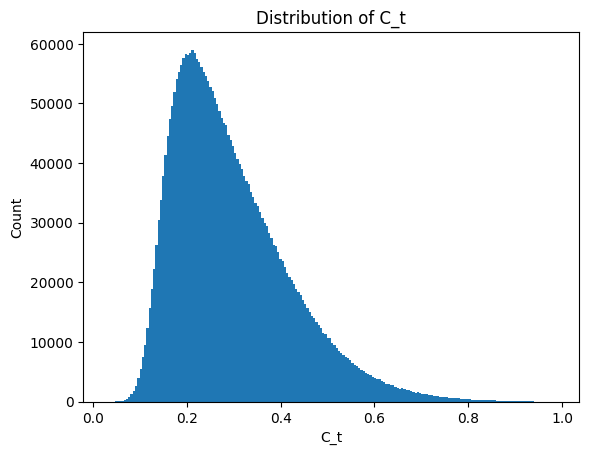

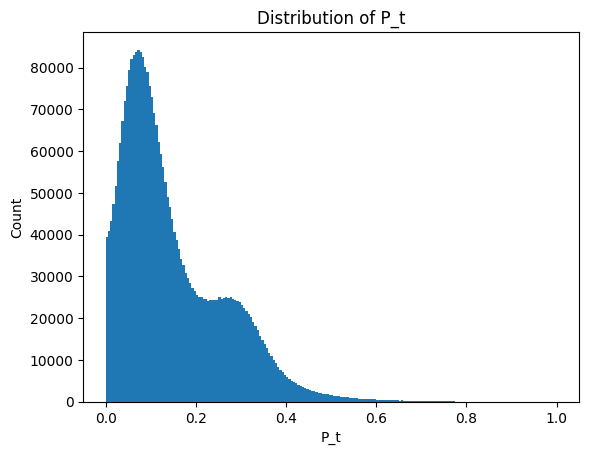

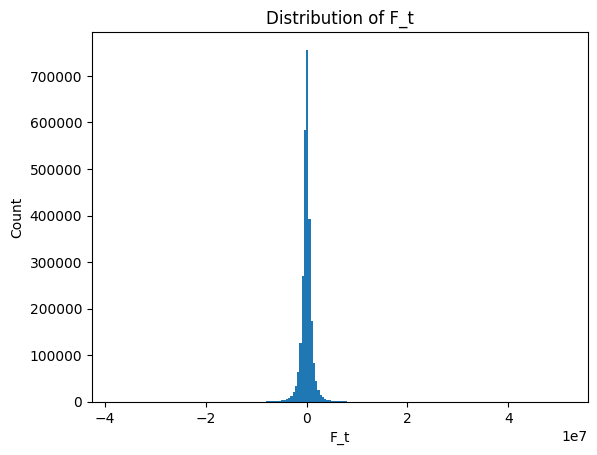

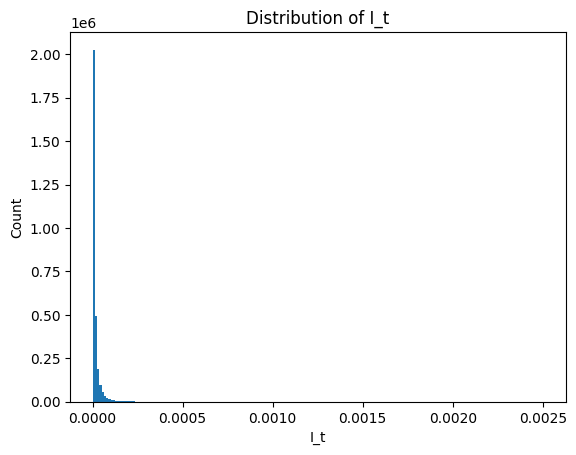

In [ ]:
import matplotlib.pyplot as plt

cols = [
    "A_t",
    "V_t",
    "C_t",
    "P_t",
    "F_t",
    "I_t",
]

print(state_vectors.select(cols).describe())

for c in cols:
    data = state_vectors.select(c).to_series().drop_nulls().to_numpy()
    plt.figure()
    plt.hist(data, bins=200)
    plt.title(f"Distribution of {c}")
    plt.xlabel(c)
    plt.ylabel("Count")
    plt.show()

# Rolling Rank เสินเจิ้น ( fast & slow )

In [ ]:
import polars as pl
import math

def rolling_pct_via_z(col: str, window: int, min_samples: int, eps: float = 1e-12) -> pl.Expr:
    x  = pl.col(col)
    mu = x.rolling_mean(window_size=window, min_samples=min_samples)
    sd = x.rolling_std(window_size=window,  min_samples=min_samples).clip(lower_bound=eps)
    z  = (x - mu) / sd

    # pct = 0.5*(1+erf(z/sqrt(2))) using Python math.erf
    inv_sqrt2 = 1.0 / math.sqrt(2.0)
    pct = z.map_elements(
        lambda v: None if v is None else 0.5 * (1.0 + math.erf(float(v) * inv_sqrt2)),
        return_dtype=pl.Float64,
    )
    return pct.clip(0.0, 1.0)

In [ ]:
df_rank = (
    state_vectors
    .with_columns([
        pl.col("V_t").log1p().alias("V_log"),
        pl.col("F_t").alias("F_raw"),
        pl.col("F_t").abs().log1p().alias("Fabs_log"),
        pl.col("A_t").alias("A_raw"),
        pl.col("P_t").alias("P_raw"),
        pl.col("C_t").alias("C_raw"),
        pl.col("I_t_filled").alias("I_raw"),
    ])
    .with_columns([
        rolling_pct_via_z("V_log",  1440,  720).alias("rk_V_fast"),
        rolling_pct_via_z("V_log",  10080, 5000).alias("rk_V_slow"),

        rolling_pct_via_z("F_raw",  1440,  720).alias("rk_F_fast"),
        rolling_pct_via_z("F_raw", 10080, 5000).alias("rk_F_slow"),

        rolling_pct_via_z("Fabs_log",  1440,  720).alias("rk_Fabs_fast"),
        rolling_pct_via_z("Fabs_log", 10080, 5000).alias("rk_Fabs_slow"),

        rolling_pct_via_z("A_raw",     1440,  720).alias("rk_A_fast"),
        rolling_pct_via_z("A_raw",    10080, 5000).alias("rk_A_slow"),

        rolling_pct_via_z("P_raw",     1440,  720).alias("rk_P_fast"),
        rolling_pct_via_z("P_raw",    10080, 5000).alias("rk_P_slow"),

        rolling_pct_via_z("C_raw",     1440,  720).alias("rk_C_fast"),
        rolling_pct_via_z("C_raw",    10080, 5000).alias("rk_C_slow"),
    ])
)

In [ ]:
df_rank

t,open,high,low,close,vol_base,vol_quote,trade_count,buy_count,sell_count,buy_quote,sell_quote,signed_quote,vwap,trade_rate,imbalance,range,hl_pct,prev_close,ret_inbar,ret_cc,gap_oc,dt_mean_ms,dt_median_ms,dt_p90_ms,frac_dt0,active_ms,intensity_peak_1s,realized_var_inbar,dp0_frac,n_price_changes,up_ticks,down_ticks,max_up_move,max_down_move,n_returns,avg_trade_q,…,run_max,run_mean,is_sparse_stats,is_sparse_seq,is_sparse_top1,gap_ms_from_last_trade,is_no_trade_fill,is_missing_fill,A_t,F_t,P_t,C_t,V_t,I_t,eps_I,I_t_filled,V_log,F_raw,Fabs_log,A_raw,P_raw,C_raw,I_raw,rk_V_fast,rk_V_slow,rk_F_fast,rk_F_slow,rk_Fabs_fast,rk_Fabs_slow,rk_A_fast,rk_A_slow,rk_P_fast,rk_P_slow,rk_C_fast,rk_C_slow,rk_I_fast,rk_I_slow
datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,u32,f64,f64,u32,u32,u32,f64,f64,u32,f64,…,i64,f64,bool,bool,bool,i64,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2020-01-01 00:00:00,129.16,129.19,128.96,129.02,305.44687,39416.984623,90.0,27.0,63.0,12240.154502,27176.830121,-14936.675619,129.046942,1.5,-0.37894,0.23,0.001782,null,-0.001085,null,null,653.370787,260.0,1765.0,0.033708,87,7,0.000002,0.539326,41,16,25,0.06,-0.06,89,3.393854,…,27,4.090909,false,false,false,0,false,false,0.00145,null,0.187391,0.232843,0.001296,0.000009,0.039417,0.000009,0.001296,null,null,0.00145,0.187391,0.232843,0.000009,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2020-01-01 00:01:00,128.99,129.11,128.99,129.02,118.00168,15228.324945,39.0,16.0,23.0,9995.54286,5232.782085,4762.760775,129.051764,0.65,0.312757,0.12,0.00093,129.02,0.000233,0.0,-0.000233,1428.289474,538.5,3537.0,0.078947,36,9,3.6627e-7,0.5,19,11,8,0.03,-0.03,38,3.025684,…,13,2.6,false,false,true,0,false,false,0.0006,null,0.039663,null,0.000605,0.000006,0.015228,0.000006,0.000605,null,null,0.0006,0.039663,null,0.000006,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2020-01-01 00:02:00,129.0,129.05,128.94,128.98,141.64707,18268.673987,37.0,19.0,18.0,16285.746282,1982.927705,14302.818578,128.973187,0.616667,0.782915,0.11,0.000853,129.02,-0.000155,-0.00031,-0.000155,1629.222222,970.5,4154.0,0.055556,35,5,9.1361e-7,0.25,27,13,14,0.05,-0.05,36,3.828299,…,8,3.7,false,false,true,0,false,false,0.000583,null,0.095848,null,0.000956,0.000001,0.018269,0.000001,0.000955,null,null,0.000583,0.095848,null,0.000001,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2020-01-01 00:03:00,128.95,129.02,128.94,128.98,29.11515,3755.064313,34.0,17.0,17.0,2057.377643,1697.686671,359.690972,128.972865,0.566667,0.095788,0.08,0.00062,128.98,0.000233,0.0,-0.000233,1763.181818,1261.0,4452.0,0.030303,33,5,6.4318e-7,0.393939,20,11,9,0.05,-0.05,33,0.856328,…,5,2.266667,false,false,true,0,false,false,0.00055,null,0.008887,null,0.000802,0.000083,0.003755,0.000083,0.000802,null,null,0.00055,0.008887,null,0.000083,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2020-01-01 00:04:00,128.97,128.97,128.8,128.88,102.50335,13209.658272,52.0,25.0,27.0,7735.141044,5474.517228,2260.623816,128.870503,0.866667,0.171134,0.17,0.001319,128.98,-0.000698,-0.000776,-0.000078,1124.313725,305.0,3804.0,0.196078,42,9,0.000001,0.352941,33,13,20,0.05,-0.04,51,1.971218,…,11,3.714286,false,false,false,0,false,false,0.0007,null,0.091812,0.390877,0.001067,0.00004,0.01321,0.00004,0.001066,null,null,0.0007,0.091812,0.390877,0.00004,null,null,null,null,null,null,null,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2025-12-31 23:55:00,2971.14,2971.82,2971.13,2971.82,22.8505,67897.53557,139.0,117.0,22.0,64144.830718,3752.704852,60392.125866,2971.380739,2.316667,0.88946,0.69,0.000232,2971.13,0.000229,0.000232,0.000003,430.536232,1.0,1357.0,0.456522,76,45,1.6535e-9,0.449275,76,64,12,0.

## Plot

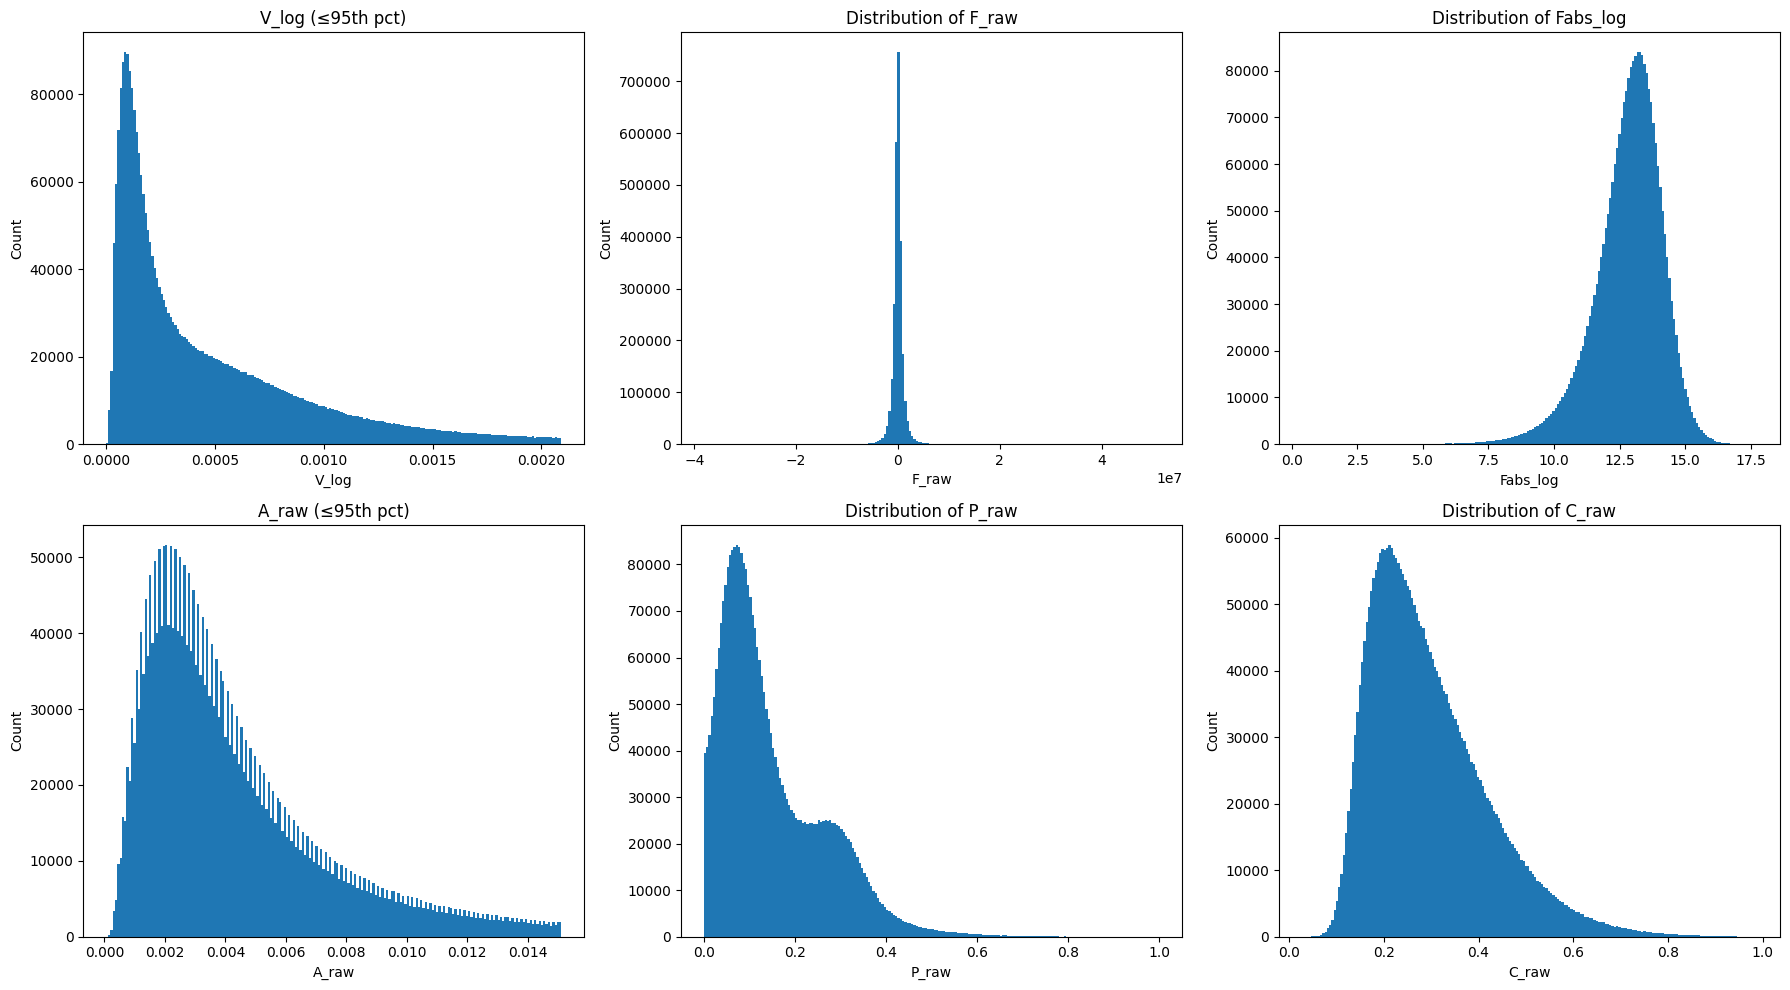

statistic,V_log,F_raw,Fabs_log,A_raw,P_raw,C_raw,I_raw
str,f64,f64,f64,f64,f64,f64,f64
"""count""",3.153974e6,2.668868e6,2.668868e6,3.153978e6,3.151751e6,3.093724e6,3.15413e6
"""null_count""",2506.0,487612.0,487612.0,2502.0,4729.0,62756.0,2350.0
"""mean""",0.000672,-8927.028411,12.825293,0.005351,0.149353,0.295287,0.000016
"""std""",0.00181,1.2259e6,1.304159,0.006602,0.113825,0.124132,0.000031
"""min""",0.0,-3.8130e7,0.375302,0.00005,0.0,0.026823,0.0
"""25%""",0.000135,-442728.605301,12.134508,0.00215,0.064194,0.202033,0.000003
"""50%""",0.000328,-3274.809323,12.982815,0.003583,0.11475,0.269659,0.000007
"""75%""",0.000768,427273.733315,13.694906,0.00615,0.2178,0.3644,0.000016
"""max""",0.678238,5.1337e7,17.753922,0.418883,1.0,0.98844,0.002503


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

cols = [
    "V_log",
    "F_raw",
    "Fabs_log",
    "A_raw",
    "P_raw",
    "C_raw",
    "I_raw"
]

special_cols = ["A_raw", "V_log", "I_raw"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, c in zip(axes, cols):
    data = df_rank.select(c).to_series().drop_nulls().to_numpy()

    if c in special_cols:
        p95 = np.percentile(data, 95)
        data = data[data < p95]
        ax.set_title(f"{c} (≤95th pct)")
    else:
        ax.set_title(f"Distribution of {c}")

    ax.hist(data, bins=200)
    ax.set_xlabel(c)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

df_rank.select(cols).describe()

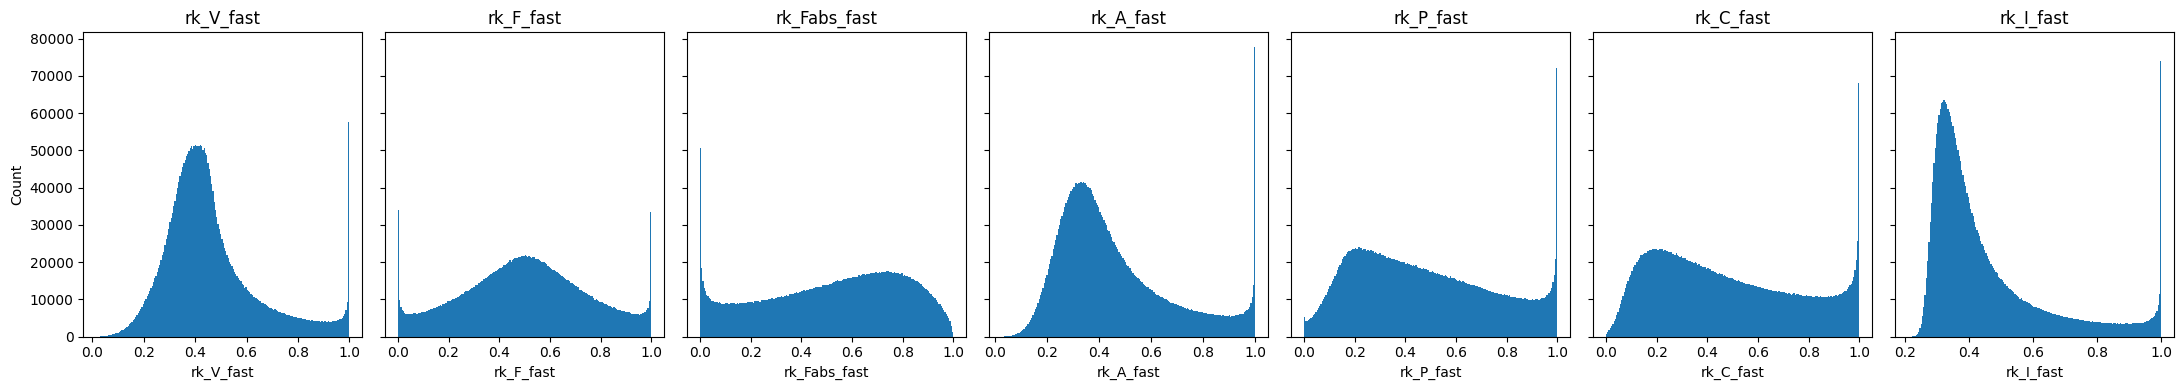

statistic,rk_V_fast,rk_F_fast,rk_Fabs_fast,rk_A_fast,rk_P_fast,rk_C_fast,rk_I_fast
str,f64,f64,f64,f64,f64,f64,f64
"""count""",3.153255e6,2.545736e6,2.545736e6,3.153259e6,3.151032e6,3.08897e6,3.153411e6
"""null_count""",3225.0,610744.0,610744.0,3221.0,5448.0,67510.0,3069.0
"""mean""",0.463478,0.500498,0.51983,0.459413,0.477195,0.476464,0.457846
"""std""",0.184894,0.243432,0.274027,0.216714,0.268254,0.277996,0.188513
"""min""",0.01325,0.0,0.0,0.026719,9.2037e-10,0.000083,0.208955
"""25%""",0.345259,0.333,0.304116,0.302324,0.252434,0.238903,0.327854
"""50%""",0.423691,0.501549,0.55519,0.399195,0.439617,0.429388,0.386926
"""75%""",0.531987,0.667981,0.747545,0.567117,0.68272,0.700289,0.515808
"""max""",1.0,1.0,0.999808,1.0,1.0,1.0,1.0


In [ ]:
import matplotlib.pyplot as plt

cols = [
    "rk_V_fast",
    "rk_F_fast",
    "rk_Fabs_fast",
    "rk_A_fast",
    "rk_P_fast",
    "rk_C_fast",
]

fig, axes = plt.subplots(1, len(cols), figsize=(22, 4), sharey=True)

for ax, c in zip(axes, cols):
    data = df_rank.select(c).to_series().drop_nulls().to_numpy()
    ax.hist(data, bins=200)
    ax.set_title(c)
    ax.set_xlabel(c)

axes[0].set_ylabel("Count")

plt.tight_layout()
plt.show()

df_rank.select(cols).describe()

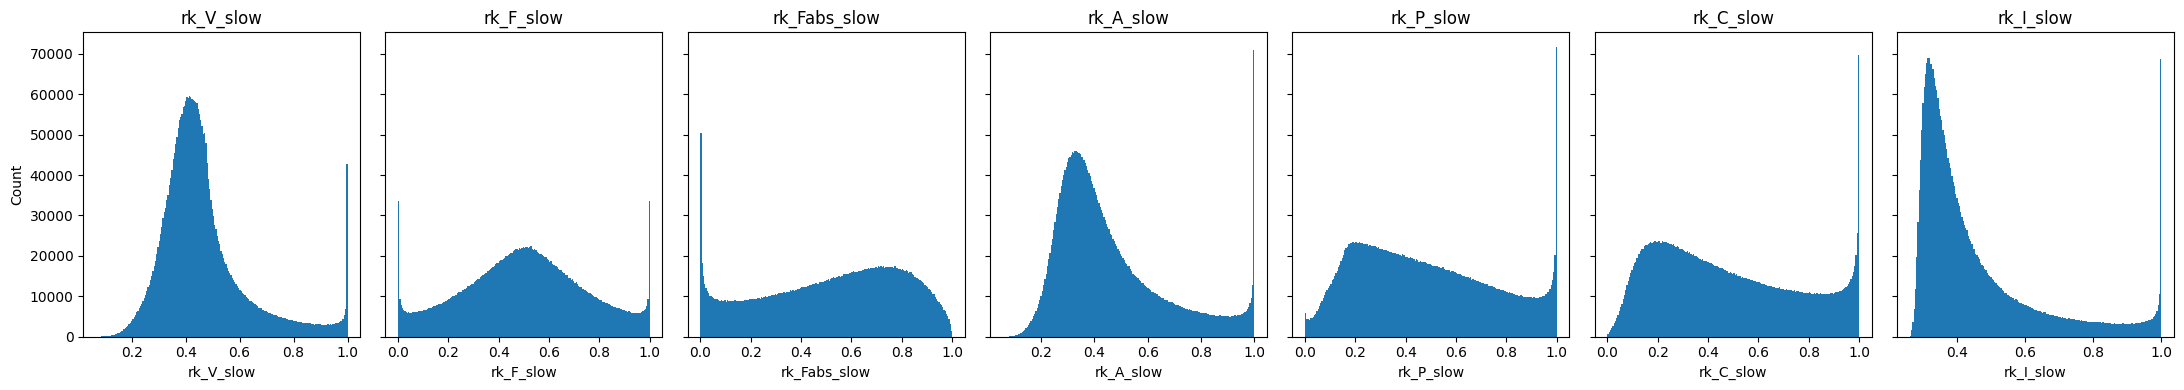

statistic,rk_V_slow,rk_F_slow,rk_Fabs_slow,rk_A_slow,rk_P_slow,rk_C_slow,rk_I_slow
str,f64,f64,f64,f64,f64,f64,f64
"""count""",3.148975e6,2.539191e6,2.539191e6,3.148979e6,3.146752e6,3.088725e6,3.149131e6
"""null_count""",7505.0,617289.0,617289.0,7501.0,9728.0,67755.0,7349.0
"""mean""",0.466972,0.500359,0.520015,0.462297,0.478286,0.476464,0.458913
"""std""",0.160944,0.241457,0.274208,0.205862,0.266741,0.277248,0.184247
"""min""",0.067178,0.0,0.0,0.055987,1.1879e-8,0.000076,0.261659
"""25%""",0.368395,0.33561,0.304054,0.314351,0.25462,0.239906,0.331375
"""50%""",0.432934,0.501528,0.55523,0.400947,0.443595,0.428936,0.387603
"""75%""",0.515638,0.664857,0.74801,0.557073,0.681727,0.698827,0.51361
"""max""",1.0,1.0,0.99978,1.0,1.0,1.0,1.0


In [ ]:
import matplotlib.pyplot as plt

cols = [
    "rk_V_slow",
    "rk_F_slow",
    "rk_Fabs_slow",
    "rk_A_slow",
    "rk_P_slow",
    "rk_C_slow",
]

fig, axes = plt.subplots(1, len(cols), figsize=(22, 4), sharey=True)

for ax, c in zip(axes, cols):
    data = df_rank.select(c).to_series().drop_nulls().to_numpy()
    ax.hist(data, bins=200)
    ax.set_title(c)
    ax.set_xlabel(c)

axes[0].set_ylabel("Count")

plt.tight_layout()
plt.show()

df_rank.select(cols).describe()

# Delta Fast vs Slow

In [ ]:
# def add_delta_rank(df, base_cols,
#                    prefix_fast="rk_", suffix_fast="_fast",
#                    prefix_slow="rk_", suffix_slow="_slow",
#                    delta_prefix="delta_"):
#     exprs = []
#     for c in base_cols:
#         fast = f"{prefix_fast}{c}{suffix_fast}"
#         slow = f"{prefix_slow}{c}{suffix_slow}"
#         delta = f"{delta_prefix}{c}"
#         exprs.append((pl.col(fast) - pl.col(slow)).alias(delta))
#     return df.with_columns(exprs)

# def plot_delta_hist_onefig(df, cols, bins=200, clip=None, ncols=3, figsize=None):
#     """
#     Plot all delta columns in ONE figure using subplots.

#     cols: list[str] เช่น ["delta_V","delta_A",...]
#     clip: (lo,hi) หรือ None
#     ncols: จำนวนคอลัมน์ในกริด
#     figsize: ถ้า None จะ auto ตาม nrows,ncols
#     """
#     n = len(cols)
#     nrows = math.ceil(n / ncols)

#     if figsize is None:
#         figsize = (5 * ncols, 4 * nrows)

#     fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
#     axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

#     for ax, c in zip(axes, cols):
#         data = df.select(pl.col(c)).drop_nulls().to_numpy().ravel()
#         if clip is not None:
#             lo, hi = clip
#             data = data[(data >= lo) & (data <= hi)]

#         ax.hist(data, bins=bins)
#         ax.set_title(f"Distribution of {c}")
#         ax.set_xlabel(c)
#         ax.set_ylabel("Count")

#     # ปิดช่องที่เหลือถ้าไม่เต็มกริด
#     for ax in axes[len(cols):]:
#         ax.axis("off")

#     plt.tight_layout()
#     plt.show()

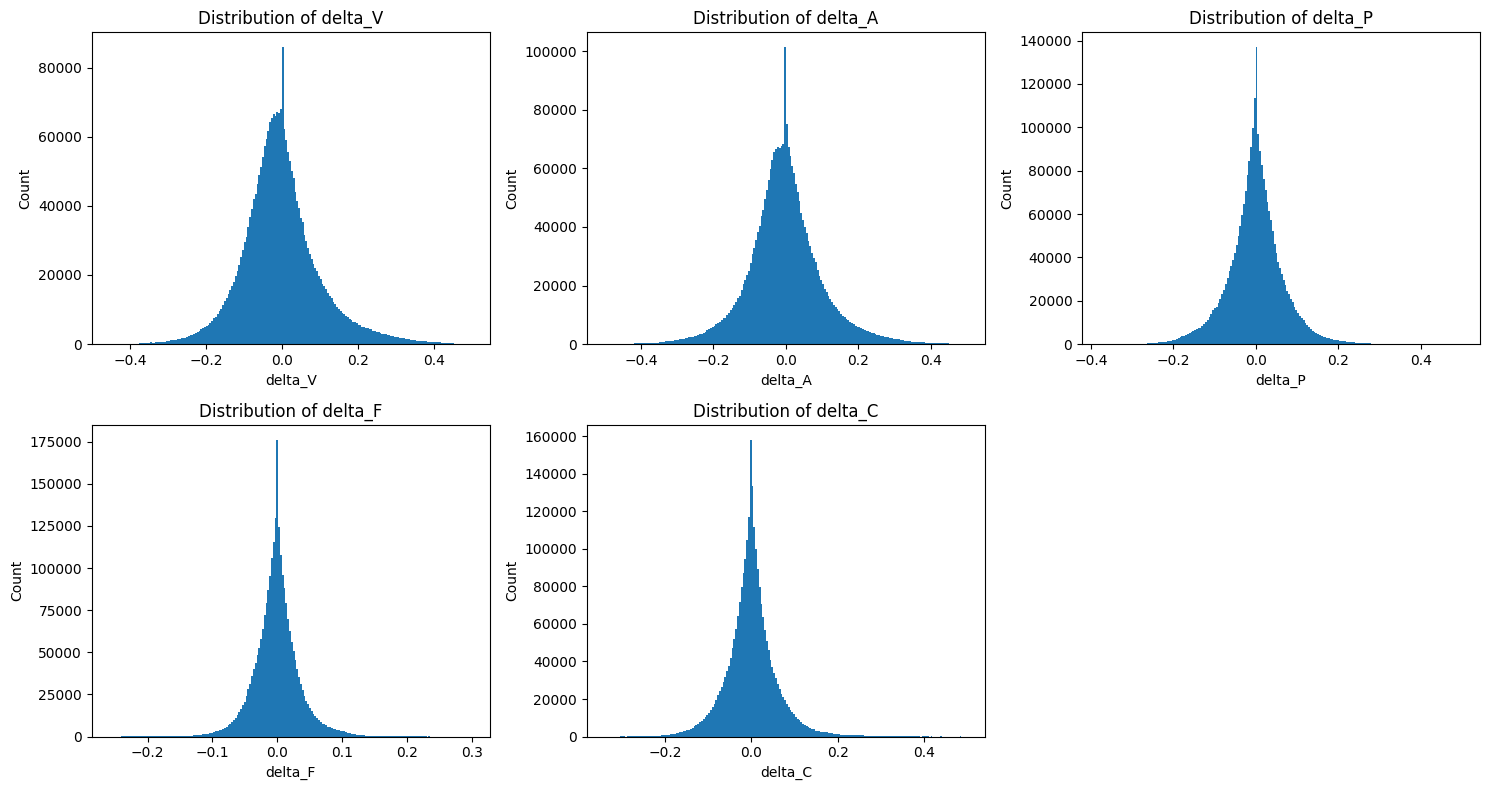

In [ ]:
df_delta = add_delta_rank(
    df_rank,
    base_cols=["V", "F", "A", "P", "C","I"],
)

plot_delta_hist_onefig(
    df_delta,
    cols=["delta_V", "delta_A", "delta_P", "delta_F", "delta_C"],
    bins=200,
    clip=(-0.5, 0.5),
    ncols=3,
)

In [ ]:
df_delta

t,open,high,low,close,vol_base,vol_quote,trade_count,buy_count,sell_count,buy_quote,sell_quote,signed_quote,vwap,trade_rate,imbalance,range,hl_pct,prev_close,ret_inbar,ret_cc,gap_oc,dt_mean_ms,dt_median_ms,dt_p90_ms,frac_dt0,active_ms,intensity_peak_1s,realized_var_inbar,dp0_frac,n_price_changes,up_ticks,down_ticks,max_up_move,max_down_move,avg_trade_q,avg_trade_notional,…,n_trans,run_max,run_mean,gap_ms_from_last_trade,is_no_trade_fill,is_missing_fill,A_t,F_t,P_t,C_t,V_t,I_t,eps_I,V_log,Fabs_log,A_raw,P_raw,C_raw,I_raw,rk_V_fast,rk_V_slow,rk_F_fast,rk_F_slow,rk_A_fast,rk_A_slow,rk_P_fast,rk_P_slow,rk_C_fast,rk_C_slow,rk_I_fast,rk_I_slow,delta_V,delta_F,delta_A,delta_P,delta_C,delta_I
datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,i64,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2020-01-01 00:00:00,129.16,129.19,128.96,129.02,305.44687,39416.984623,90.0,27.0,63.0,12240.154502,27176.830121,-14936.675619,129.046942,1.5,-0.37894,0.23,0.001782,null,-0.001085,null,null,653.370787,260.0,1765.0,0.033708,87.0,7.0,0.000002,0.539326,41.0,16.0,25.0,0.06,-0.06,3.393854,437.966496,…,89.0,27.0,4.090909,0,false,false,0.00145,-149366.756192,0.187391,0.232843,0.001296,0.000009,0.039417,0.001296,11.914167,0.00145,0.187391,0.232843,0.000009,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2020-01-01 00:01:00,128.99,129.11,128.99,129.02,118.00168,15228.324945,39.0,16.0,23.0,9995.54286,5232.782085,4762.760775,129.051764,0.65,0.312757,0.12,0.00093,129.02,0.000233,0.0,-0.000233,1428.289474,538.5,3537.0,0.078947,36.0,9.0,3.6627e-7,0.5,19.0,11.0,8.0,0.03,-0.03,3.025684,390.46987,…,38.0,13.0,2.6,0,false,false,0.0006,47627.607754,0.039663,0.432197,0.000605,0.000006,0.015228,0.000605,10.771189,0.0006,0.039663,0.432197,0.000006,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2020-01-01 00:02:00,129.0,129.05,128.94,128.98,141.64707,18268.673987,37.0,19.0,18.0,16285.746282,1982.927705,14302.818578,128.973187,0.616667,0.782915,0.11,0.000853,129.02,-0.000155,-0.00031,-0.000155,1629.222222,970.5,4154.0,0.055556,35.0,5.0,9.1361e-7,0.25,27.0,13.0,14.0,0.05,-0.05,3.828299,493.747946,…,36.0,8.0,3.7,0,false,false,0.000583,143028.185775,0.095848,0.136871,0.000956,0.000001,0.018269,0.000955,11.870804,0.000583,0.095848,0.136871,0.000001,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2020-01-01 00:03:00,128.95,129.02,128.94,128.98,29.11515,3755.064313,34.0,17.0,17.0,2057.377643,1697.686671,359.690972,128.972865,0.566667,0.095788,0.08,0.00062,128.98,0.000233,0.0,-0.000233,1763.181818,1261.0,4452.0,0.030303,33.0,5.0,6.4318e-7,0.393939,20.0,11.0,9.0,0.05,-0.05,0.856328,110.443068,…,33.0,5.0,2.266667,0,false,false,0.00055,3596.909716,0.008887,0.274771,0.000802,0.000083,0.003755,0.000802,8.188108,0.00055,0.008887,0.274771,0.000083,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2020-01-01 00:04:00,128.97,128.97,128.8,128.88,102.50335,13209.658272,52.0,25.0,27.0,7735.141044,5474.517228,2260.623816,128.870503,0.866667,0.171134,0.17,0.001319,128.98,-0.000698,-0.000776,-0.000078,1124.313725,305.0,3804.0,0.196078,42.0,9.0,0.000001,0.352941,33.0,13.0,20.0,0.05,-0.04,1.971218,254.03189,…,51.0,11.0,3.714286,0,false,false,0.0007,22606.238157,0.091812,0.390877,0.001067,0.00004,0.01321,0.001066,10.026025,0.0007,0.091812,0.390877,0.00004,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-12-31 23:55:00,3340.49,3341.74,3340.48,3341.74,36.0196,120337.937573,130.0,118.0,12.0,119769.699469,568.238104,119201.461365,3340.901553

# Finish

In [ ]:
df_rank.write_parquet(str(data_path("0.Data -> Facts/phase_data/phase_1_ETH_1min_Market_Structure_Feature.parquet")))